# Esploratore dei gate e dei canali del modello MNTB

Dato uno (o più) file `.nestml`, questo notebook legge i parametri e disegna, in funzione della tensione:

1. **ogni gate** (m, h, l, r, n, p, …): α(V), β(V), valore a regime x∞(V) e costante di tempo τ(V);
2. una **tabella** con V½ e pendenza di ogni gate e τ a tensioni scelte;
3. **ogni canale**: frazione di conduttanza aperta a regime e corrente a regime;
4. la **composizione della corrente di potassio** (I_LT vs I_Kv3) a diverse tensioni;
5. l'**evoluzione nel tempo dei gate** durante un gradino di tensione.

**Equazioni** (stessa forma di Wang 1998 / Macica 2003 / Desai 2008):

$$\frac{dx}{dt}=\alpha_x(1-x)-\beta_x x,\qquad \alpha_x=k_{\alpha x}e^{\eta_{\alpha x}V},\qquad \beta_x=k_{\beta x}e^{\eta_{\beta x}V}$$

$$x_\infty=\frac{\alpha_x}{\alpha_x+\beta_x}=\frac{1}{1+e^{-(V-V_{1/2})/s}},\qquad \tau_x=\frac{1}{\alpha_x+\beta_x},\qquad V_{1/2}=\frac{\ln(k_{\beta x}/k_{\alpha x})}{\eta_{\alpha x}-\eta_{\beta x}},\quad s=\frac{1}{\eta_{\alpha x}-\eta_{\beta x}}$$

Se s è positivo il gate si **apre** con la depolarizzazione (attivazione), se è negativo si **chiude** (inattivazione).

**Confrontare modelli:** in `MODELS` potete mettere più file, oppure lo stesso file con dei parametri cambiati al volo
(es. `{"eta_alpha_n": 0.06}`) senza modificare il `.nestml`. Ogni modello ha uno stile di linea diverso.

In [24]:
import re
import numpy as np
import matplotlib.pyplot as plt

# ======================= impostazioni =======================
# nome mostrato in legenda -> (file .nestml, parametri da sovrascrivere)
MODELS = {
    "originale":      ("mntb_hh_kv3_neuron_prova.nestml", {}),
    "η_αn = 0.06":    ("mntb_hh_kv3_neuron_prova.nestml", {"eta_alpha_n": 0.06}),
}
V = np.linspace(-100, 60, 641)          # mV, asse delle tensioni
V_TABLE = [-80, -60, -40, -20, 0, 20, 40]   # tensioni per la tabella delle τ
V_COMPOSITION = [-60, -40, -30, -20, -10, 0]   # tensioni per la composizione della corrente K
V_STEPS = [-40, -20, 0, 40]             # gradini per l'evoluzione temporale dei gate
V_HOLD = -80                            # potenziale di partenza dei gradini
SAVE_FIGS = False                       # True per salvare le figure in FIG_DIR
FIG_DIR = "figures"

# Colori (palette categorica in ordine fisso) e stili di linea per i modelli
COLORS = ["#257de0", "#f47230", "#00b894", "#f2a600", "#ee7fac", "#008a17", "#6a4ce2", "#ec4647"]
STYLES = ["-", "--", ":", "-."]
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10})


def read_nestml_parameters(path):
    """Legge i valori numerici del blocco `parameters:` di un file NESTML ({nome: valore})."""
    params, inside = {}, False
    for line in open(path):
        code = line.split("#")[0].rstrip()
        if not code.strip():
            continue
        indent = len(code) - len(code.lstrip())
        if code.strip() == "parameters:":
            inside, block_indent = True, indent
            continue
        if inside:
            if indent <= block_indent:
                break
            m = re.match(r"\s*(\w+)\s+[\w/]+\s*=\s*([-+]?[0-9.]+(?:[eE][-+]?\d+)?)", code)
            if m:
                params[m.group(1)] = float(m.group(2))
    return params


def find_gates(P):
    """Tutti i gate x per cui esistono k_alpha_x, eta_alpha_x, k_beta_x, eta_beta_x."""
    gates = []
    for key in P:
        if key.startswith("k_alpha_"):
            g = key[len("k_alpha_"):]
            if all(f"{k}_{g}" in P for k in ("eta_alpha", "k_beta", "eta_beta")):
                gates.append(g)
    return gates


PARAMS = {}
for name, (path, overrides) in MODELS.items():
    P = read_nestml_parameters(path)
    unknown = [k for k in overrides if k not in P]
    assert not unknown, f"{name}: parametri non presenti in {path}: {unknown}"
    P.update(overrides)
    PARAMS[name] = P

GATES = []
for P in PARAMS.values():
    GATES += [g for g in find_gates(P) if g not in GATES]
GATE_COLOR = {g: COLORS[i % len(COLORS)] for i, g in enumerate(GATES)}
print("Gate trovati:", GATES)
for name, (path, ov) in MODELS.items():
    print(f"  {name}: {path}  {ov if ov else ''}")

Gate trovati: ['m', 'h', 'l', 'r', 'n', 'p']
  originale: mntb_hh_kv3_neuron_prova.nestml  
  η_αn = 0.06: mntb_hh_kv3_neuron_prova.nestml  {'eta_alpha_n': 0.06}


In [25]:
# ======================= funzioni dei gate =======================
def rates(P, g, V):
    a = P["k_alpha_" + g] * np.exp(P["eta_alpha_" + g] * V)
    b = P["k_beta_" + g] * np.exp(P["eta_beta_" + g] * V)
    return a, b


def x_inf(P, g, V):
    a, b = rates(P, g, V)
    return a / (a + b)


def tau(P, g, V):
    a, b = rates(P, g, V)
    return 1.0 / (a + b)


def half_and_slope(P, g):
    """V½ (mV) e pendenza s (mV) analitiche di x∞. s > 0: attivazione, s < 0: inattivazione."""
    d = P["eta_alpha_" + g] - P["eta_beta_" + g]
    if abs(d) < 1e-12:
        return np.nan, np.inf          # x∞ costante: il gate non dipende dalla tensione
    return np.log(P["k_beta_" + g] / P["k_alpha_" + g]) / d, 1.0 / d


def savefig(name):
    if SAVE_FIGS:
        import os
        os.makedirs(FIG_DIR, exist_ok=True)
        plt.savefig(f"{FIG_DIR}/{name}.png", dpi=130, bbox_inches="tight")

## 1. I gate: α, β, x∞ e τ
Una riga per gate. Colonne: velocità di apertura α e di chiusura β (scala logaritmica), valore a regime x∞,
costante di tempo τ (scala logaritmica, perché va da frazioni di ms a centinaia di ms).

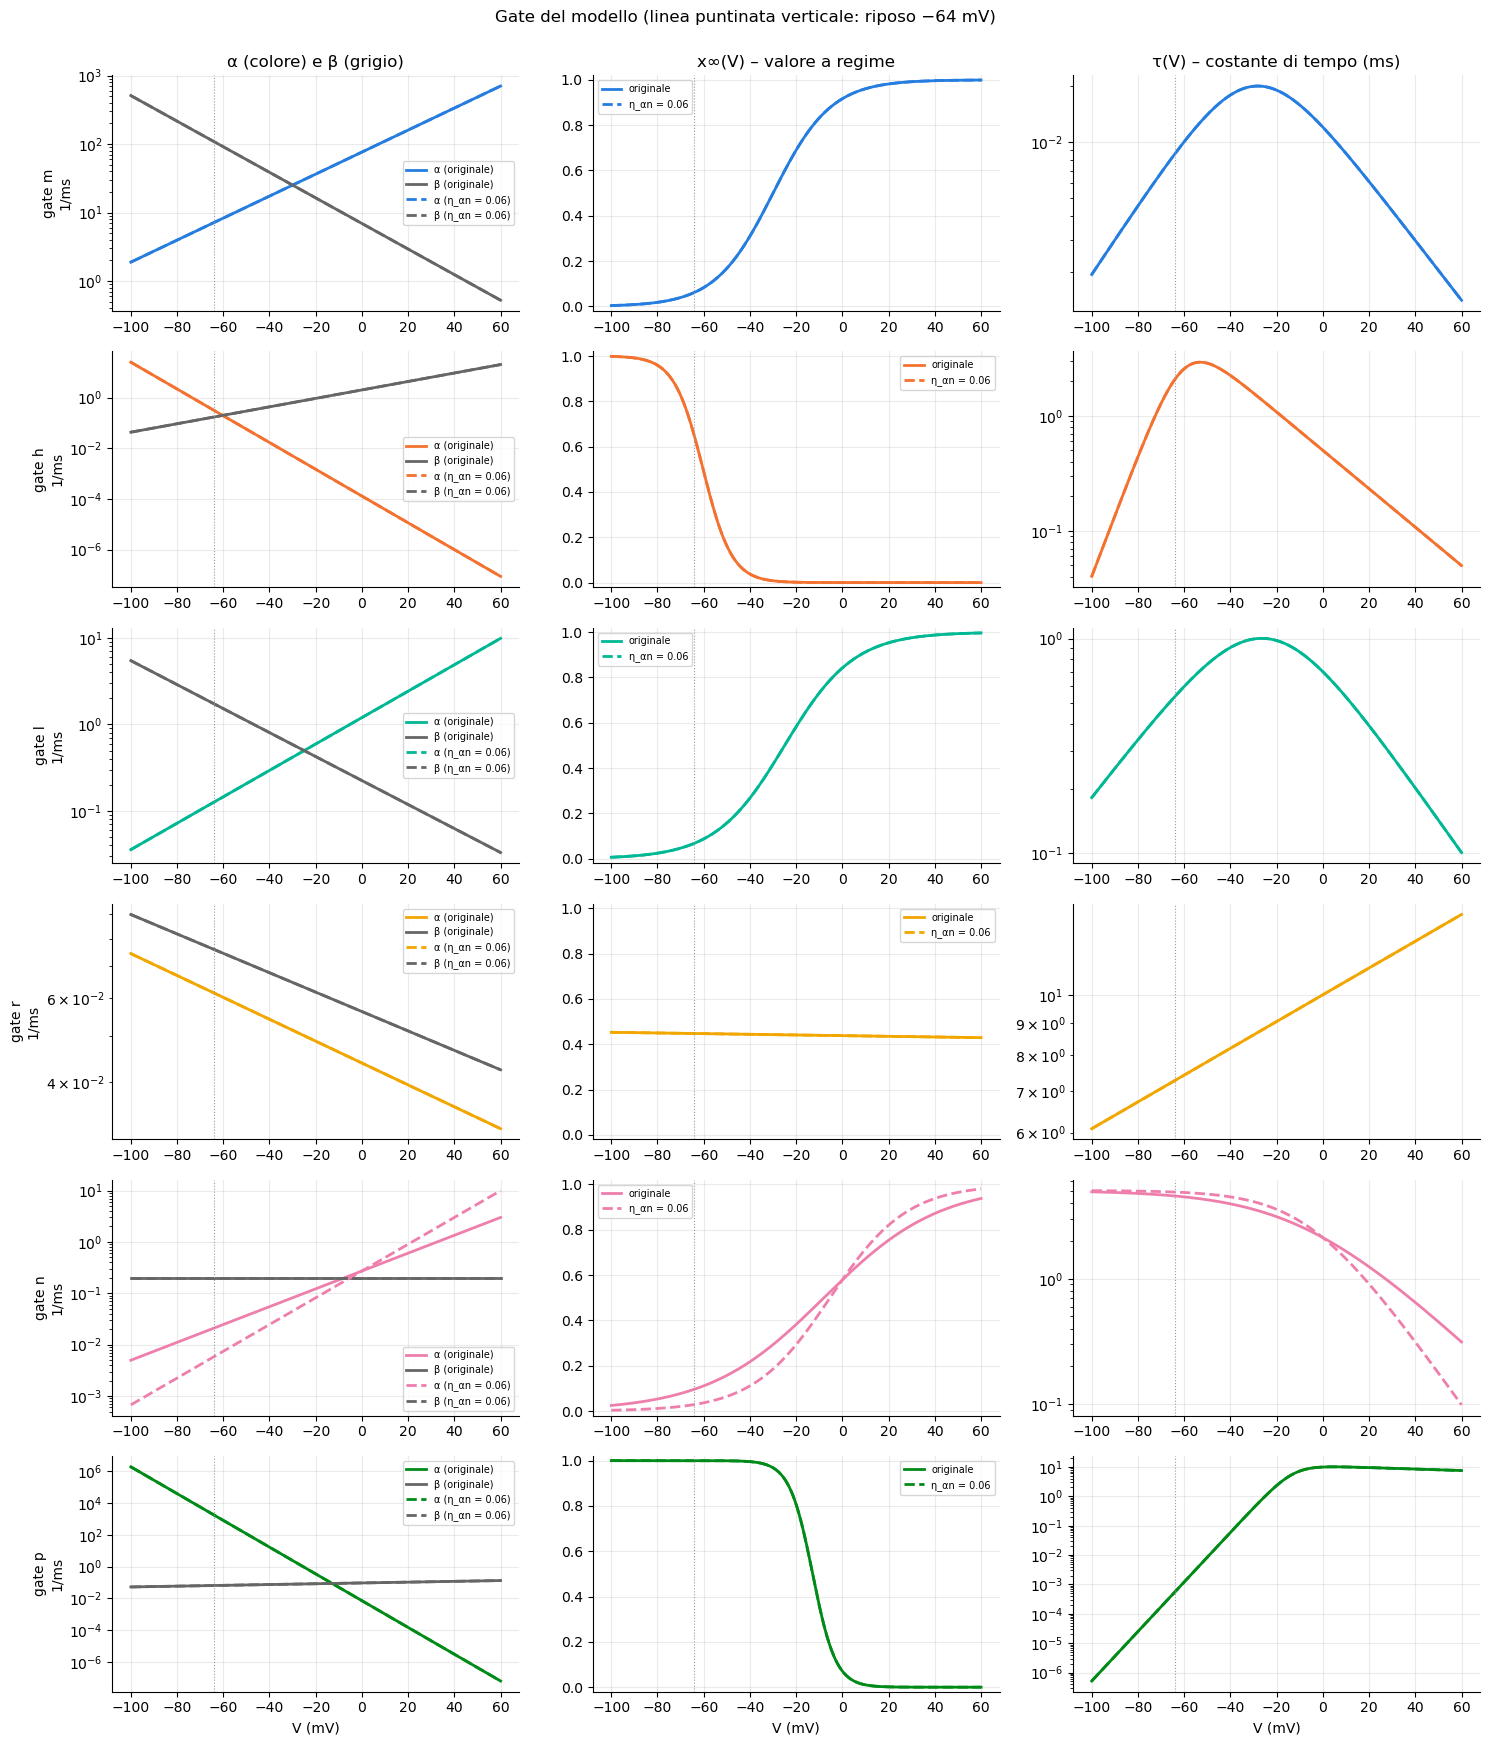

In [26]:
fig, axes = plt.subplots(len(GATES), 3, figsize=(15, 2.9 * len(GATES)), squeeze=False)
for i, g in enumerate(GATES):
    ax_r, ax_inf, ax_tau = axes[i]
    for j, (name, P) in enumerate(PARAMS.items()):
        if g not in find_gates(P):
            continue
        ls = STYLES[j % len(STYLES)]
        a, b = rates(P, g, V)
        ax_r.semilogy(V, a, ls, color=GATE_COLOR[g], label=f"α ({name})")
        ax_r.semilogy(V, b, ls, color="#666666", label=f"β ({name})")
        ax_inf.plot(V, x_inf(P, g, V), ls, color=GATE_COLOR[g], label=name)
        ax_tau.semilogy(V, tau(P, g, V), ls, color=GATE_COLOR[g], label=name)
    ax_r.set_ylabel(f"gate {g}\n1/ms")
    ax_inf.set_ylim(-0.02, 1.02)
    for ax in (ax_r, ax_inf, ax_tau):
        ax.axvline(-64, color="#999999", lw=0.8, ls=":")      # riposo
    if i == 0:
        ax_r.set_title("α (colore) e β (grigio)")
        ax_inf.set_title("x∞(V) – valore a regime")
        ax_tau.set_title("τ(V) – costante di tempo (ms)")
    ax_r.legend(fontsize=7, loc="best")
    ax_inf.legend(fontsize=7, loc="best")
for ax in axes[-1]:
    ax.set_xlabel("V (mV)")
fig.suptitle("Gate del modello (linea puntinata verticale: riposo −64 mV)", y=1.0)
plt.tight_layout(); savefig("gate_alpha_beta_inf_tau"); plt.show()

## 2. Tabella: V½, pendenza e τ a tensioni scelte
V½ e s sono quelli di x∞ (formula analitica). Ricordate che per un canale con x³ (es. n³) la curva della
**corrente** è più a destra e più ripida di quella del singolo gate: la vedete nella sezione 3.

In [27]:
for name, P in PARAMS.items():
    print(f"\n=== {name} ===")
    head = f"{'gate':<5}{'V½ (mV)':>9}{'s (mV)':>9}{'tipo':>14}  " + "".join(f"{'τ@'+str(v):>9}" for v in V_TABLE)
    print(head); print("-" * len(head))
    for g in find_gates(P):
        v12, s = half_and_slope(P, g)
        kind = "costante" if np.isinf(s) else ("attivazione" if s > 0 else "inattivazione")
        taus = "".join(f"{tau(P, g, v):9.3g}" for v in V_TABLE)
        print(f"{g:<5}{v12:9.1f}{s:9.1f}{kind:>14}  {taus}")
print("\nτ in ms. s = 1/(η_α − η_β): più è piccolo in valore assoluto, più la curva è ripida.")


=== originale ===
gate   V½ (mV)   s (mV)          tipo      τ@-80    τ@-60    τ@-40    τ@-20      τ@0     τ@20     τ@40
------------------------------------------------------------------------------------------------------
m        -30.0     12.5   attivazione    0.00454     0.01   0.0178   0.0189    0.012  0.00613  0.00297
h        -60.3     -6.2 inattivazione       0.44     2.56     2.24     1.08      0.5    0.232    0.108
l        -25.0     14.9   attivazione      0.338    0.599    0.909     0.98    0.702    0.394    0.202
r       -415.5  -1666.7 inattivazione       6.72     7.42      8.2     9.05       10       11     12.2
n         -8.0     25.0   attivazione        4.8      4.5     3.96     3.13     2.13     1.25    0.648
p        -12.9     -5.0 inattivazione   2.51e-05  0.00122   0.0591     2.33     9.94     9.51     8.48

=== η_αn = 0.06 ===
gate   V½ (mV)   s (mV)          tipo      τ@-80    τ@-60    τ@-40    τ@-20      τ@0     τ@20     τ@40
---------------------------------

## 3. I canali: frazione aperta e corrente a regime
Ogni canale è definito qui sotto da: i gate che usa, la formula della frazione aperta e la conduttanza.
- **frazione aperta a regime**: tutti i gate a x∞ (per Na è la "window current");
- **solo attivazione**: i gate di inattivazione lasciati a 1, cioè la curva di attivazione che si misura al picco;
- **corrente a regime** = g · frazione · (V − E): positiva = uscente (K), negativa = entrante (Na).
  Attenzione: nel `.nestml` il segno è al contrario, I = g·…·(E − V).

Quando separerete Kv3 in Kv3.1 e Kv3.3 basta aggiungere qui due canali (vedi esempio commentato):
quelli i cui gate o parametri non esistono nel modello vengono saltati.

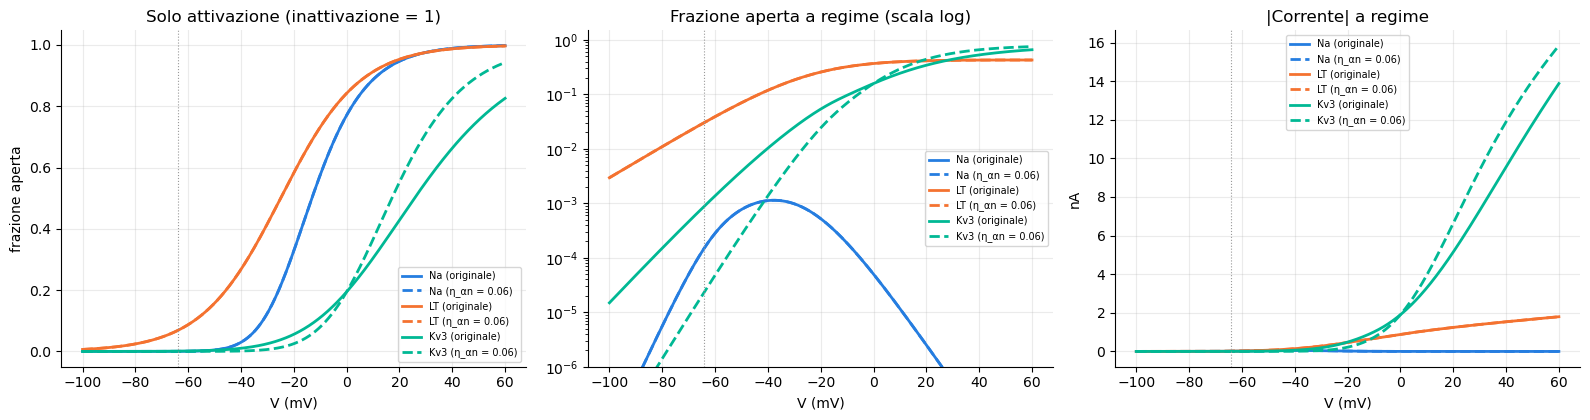

canale  modello             V½ att. (mV)   k (mV)   frazione aperta a regime a -60, -40, -20, 0 mV
Na      originale                  -12.4      9.8   0.0003  0.0011  0.0005  0.0001
Na      η_αn = 0.06                -12.4      9.8   0.0003  0.0011  0.0005  0.0001
LT      originale                  -25.1     14.8   0.0390  0.1189  0.2570  0.3689
LT      η_αn = 0.06                -25.1     14.8   0.0390  0.1189  0.2570  0.3689
Kv3     originale                   18.4     14.8   0.0014  0.0103  0.0537  0.1583
Kv3     η_αn = 0.06                 16.1     11.7   0.0000  0.0014  0.0242  0.1583


In [28]:
CHANNELS = {
    # nome: (gate richiesti, frazione aperta f(x), frazione "solo attivazione", conduttanza, inversione)
    "Na":  (["m", "h"], lambda x, P: x["m"]**3 * x["h"],              lambda x, P: x["m"]**3, "g_Na", "E_Na"),
    "LT":  (["l", "r"], lambda x, P: x["l"] * x["r"],                 lambda x, P: x["l"],    "g_LT", "E_K"),
    "Kv3": (["n", "p"], lambda x, P: x["n"]**3 * (0.8 + 0.2 * x["p"]), lambda x, P: x["n"]**3, "g_Kv3", "E_K"),
    # Esempio per lo step 2 (adattate i nomi a quelli del vostro .nestml):
    # "Kv3.1": (["n", "p31"], lambda x, P: x["n"]**3 * (0.8 + 0.2 * x["p31"]),  lambda x, P: x["n"]**3, "g_Kv3_1", "E_K"),
    # "Kv3.3": (["n", "p33"], lambda x, P: x["n"]**3 * (0.23 + 0.77 * x["p33"]), lambda x, P: x["n"]**3, "g_Kv3_3", "E_K"),
}
CH_COLOR = {c: COLORS[i % len(COLORS)] for i, c in enumerate(CHANNELS)}


def channel_curves(P, ch, V):
    gates, f_open, f_act, g_name, e_name = CHANNELS[ch]
    if not all(g in find_gates(P) for g in gates) or g_name not in P or e_name not in P:
        return None
    x = {g: x_inf(P, g, V) for g in gates}
    frac = f_open(x, P)
    act = f_act(x, P)
    I = P[g_name] * frac * (V - P[e_name])          # pA (nS * mV), positiva = uscente
    return frac, act, I


def boltzmann_fit(V, y):
    """V½ e pendenza di una curva di attivazione normalizzata (fit di Boltzmann)."""
    from scipy.optimize import curve_fit
    yn = y / y.max()
    B = lambda V, v, k: 1 / (1 + np.exp((v - V) / k))
    (v, k), _ = curve_fit(B, V, yn, p0=[V[np.argmin(np.abs(yn - 0.5))], 10])
    return v, k


fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for ch in CHANNELS:
    for j, (name, P) in enumerate(PARAMS.items()):
        res = channel_curves(P, ch, V)
        if res is None:
            continue
        frac, act, I = res
        ls = STYLES[j % len(STYLES)]
        ax[0].plot(V, act, ls, color=CH_COLOR[ch], label=f"{ch} ({name})")
        ax[1].semilogy(V, np.maximum(frac, 1e-7), ls, color=CH_COLOR[ch], label=f"{ch} ({name})")
        ax[2].plot(V, np.abs(I) / 1000, ls, color=CH_COLOR[ch], label=f"{ch} ({name})")
ax[0].set_title("Solo attivazione (inattivazione = 1)"); ax[0].set_ylabel("frazione aperta")
ax[1].set_title("Frazione aperta a regime (scala log)"); ax[1].set_ylim(1e-6, 1.5)
ax[2].set_title("|Corrente| a regime"); ax[2].set_ylabel("nA")
for a in ax:
    a.set_xlabel("V (mV)"); a.axvline(-64, color="#999999", lw=0.8, ls=":"); a.legend(fontsize=7)
plt.tight_layout(); savefig("canali_regime"); plt.show()

print(f"{'canale':<8}{'modello':<18}{'V½ att. (mV)':>14}{'k (mV)':>9}   frazione aperta a regime a " +
      ", ".join(f"{v}" for v in (-60, -40, -20, 0)) + " mV")
for ch in CHANNELS:
    for name, P in PARAMS.items():
        res = channel_curves(P, ch, V)
        if res is None:
            continue
        frac, act, _ = res
        v12, k = boltzmann_fit(V, act)
        fr = "  ".join(f"{np.interp(v, V, frac):.4f}" for v in (-60, -40, -20, 0))
        print(f"{ch:<8}{name:<18}{v12:14.1f}{k:9.1f}   {fr}")

## 4. Chi porta la corrente di potassio sotto soglia? (I_LT vs I_Kv3)
Correnti di potassio a regime nella zona sotto soglia. Secondo Wang 1998 a −40 mV Kv3 è praticamente spenta
e a −20 mV la corrente è soprattutto I_LT (DTX ne toglie il 75%).

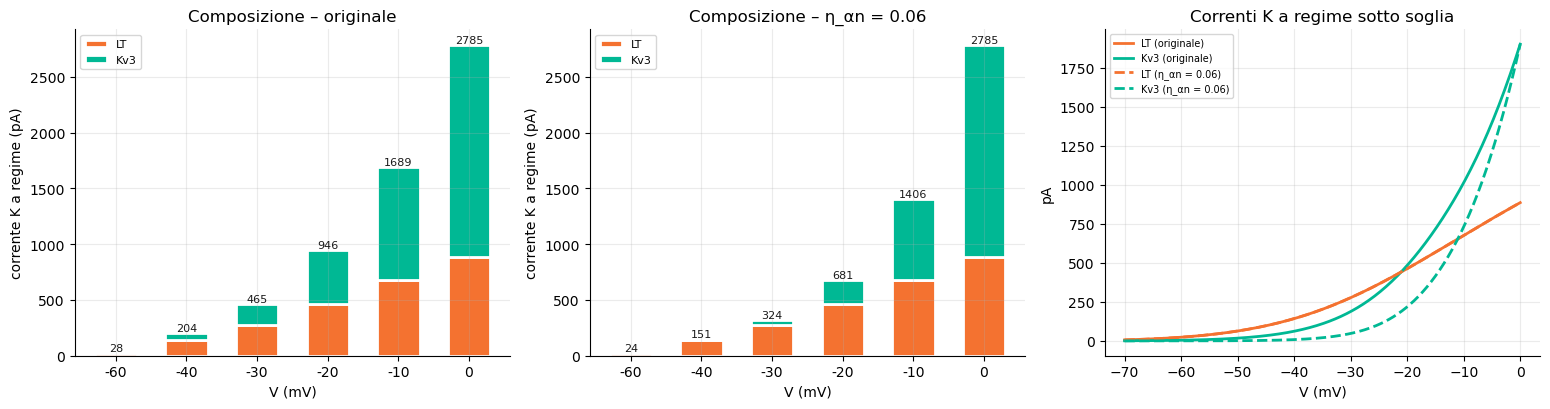

originale          a −40 / −20 mV -> LT: 143 / 463 pA (49% a −20), Kv3: 62 / 483 pA (51% a −20)
η_αn = 0.06        a −40 / −20 mV -> LT: 143 / 463 pA (68% a −20), Kv3: 8 / 218 pA (32% a −20)


In [29]:
K_CHANNELS = [c for c in CHANNELS if CHANNELS[c][4] == "E_K"]
fig, axes = plt.subplots(1, len(PARAMS) + 1, figsize=(5.2 * (len(PARAMS) + 1), 4.2), squeeze=False)
axes = axes[0]
Vsub = np.linspace(-70, 0, 281)
for j, (name, P) in enumerate(PARAMS.items()):
    ls = STYLES[j % len(STYLES)]
    for ch in K_CHANNELS:
        res = channel_curves(P, ch, Vsub)
        if res is not None:
            axes[-1].plot(Vsub, res[2], ls, color=CH_COLOR[ch], label=f"{ch} ({name})")
    # barre impilate: composizione a tensioni scelte
    ax = axes[j]
    bottom = np.zeros(len(V_COMPOSITION))
    x = np.arange(len(V_COMPOSITION))
    for ch in K_CHANNELS:
        res = channel_curves(P, ch, np.array(V_COMPOSITION, dtype=float))
        if res is None:
            continue
        I = res[2]
        ax.bar(x, I, 0.6, bottom=bottom, color=CH_COLOR[ch], label=ch, edgecolor="white", linewidth=2)
        bottom += I
    for xi, tot in zip(x, bottom):
        ax.text(xi, tot, f"{tot:.0f}", ha="center", va="bottom", fontsize=8, color="#191919")
    ax.set_xticks(x); ax.set_xticklabels([f"{v}" for v in V_COMPOSITION])
    ax.set_xlabel("V (mV)"); ax.set_ylabel("corrente K a regime (pA)")
    ax.set_title(f"Composizione – {name}"); ax.legend(fontsize=8)
axes[-1].set_title("Correnti K a regime sotto soglia"); axes[-1].set_xlabel("V (mV)"); axes[-1].set_ylabel("pA")
axes[-1].legend(fontsize=7)
plt.tight_layout(); savefig("composizione_corrente_K"); plt.show()

for name, P in PARAMS.items():
    parts = {ch: channel_curves(P, ch, np.array([-40.0, -20.0])) for ch in K_CHANNELS}
    parts = {ch: r[2] for ch, r in parts.items() if r is not None}
    tot = sum(parts.values())
    desc = ", ".join(f"{ch}: {I[0]:.0f} / {I[1]:.0f} pA ({I[1] / tot[1]:.0%} a −20)" for ch, I in parts.items())
    print(f"{name:<18} a −40 / −20 mV -> {desc}")

## 5. Evoluzione dei gate durante un gradino di tensione
Partendo dallo stato stazionario a `V_HOLD`, la tensione salta a ciascun valore di `V_STEPS`. Ogni gate segue
x(t) = x∞ + (x₀ − x∞)·e^(−t/τ): si vede quali gate sono veloci (m, n) e quali lenti (h, p, r).

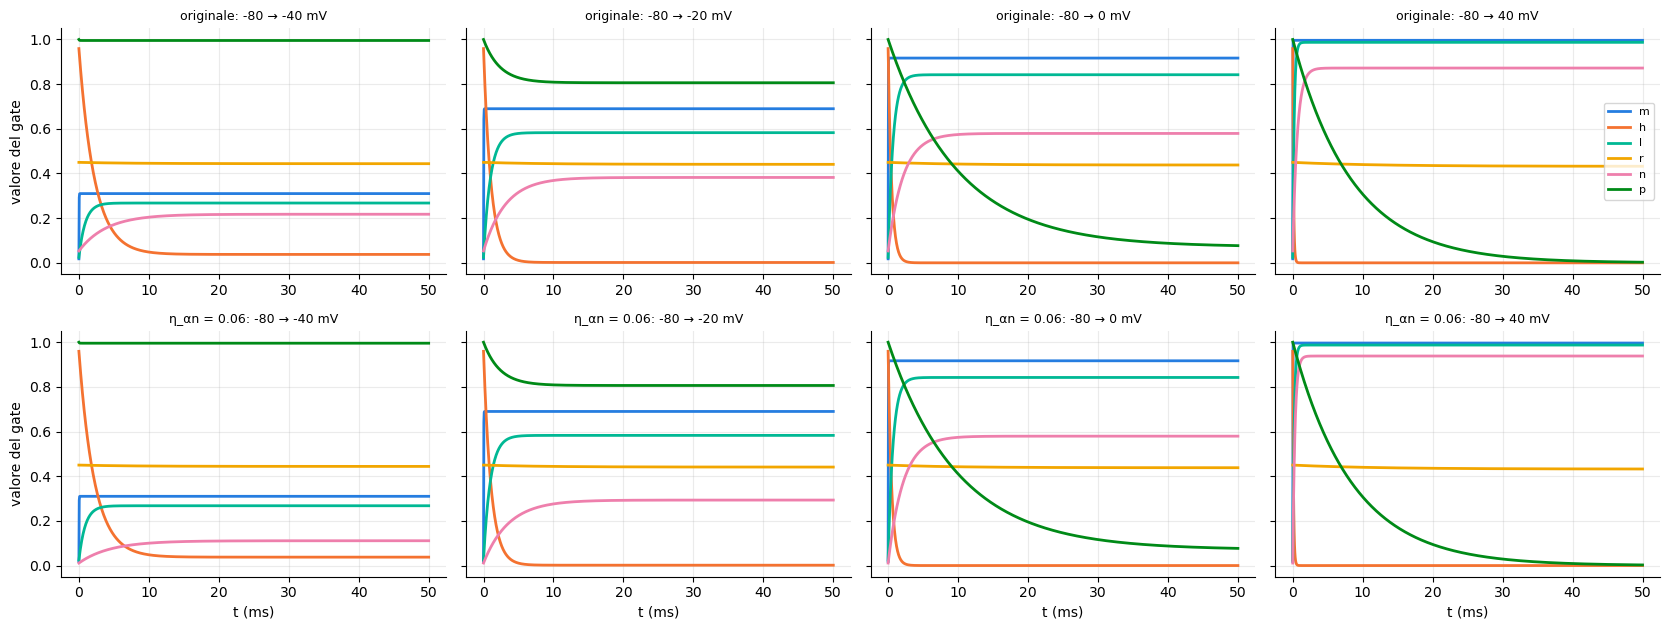

In [30]:
t = np.linspace(0, 50, 1001)            # ms
fig, axes = plt.subplots(len(PARAMS), len(V_STEPS), figsize=(4.2 * len(V_STEPS), 3.2 * len(PARAMS)),
                         squeeze=False, sharey=True)
for i, (name, P) in enumerate(PARAMS.items()):
    for k, Vs in enumerate(V_STEPS):
        ax = axes[i][k]
        for g in find_gates(P):
            x0, xi, tx = x_inf(P, g, V_HOLD), x_inf(P, g, Vs), tau(P, g, Vs)
            ax.plot(t, xi + (x0 - xi) * np.exp(-t / tx), color=GATE_COLOR[g], label=g)
        ax.set_title(f"{name}: {V_HOLD} → {Vs} mV", fontsize=9)
        if i == len(PARAMS) - 1:
            ax.set_xlabel("t (ms)")
        if k == 0:
            ax.set_ylabel("valore del gate")
axes[0][-1].legend(fontsize=8, loc="center right")
plt.tight_layout(); savefig("gate_nel_tempo"); plt.show()